# GraphSAGE enrichment ablation on the F1 KGs

Which SULO enrichments make Hybrid differ from Ad-hoc, and what does each one contribute to node
prediction (`RaceEntry` → `hasRacePoints`)? Comparing the two schemas gives five units, each ablated
on its own (`f1_node_data.ABLATION_UNITS`):

| Unit | Hybrid | Ad-hoc |
|---|---|---|
| `sulo_typing` | instances also typed with their SULO superclass (`sulo:Process`, `sulo:SpatialObject`, ...) | domain class only |
| `precedesRace` | `Race sulo:precedes Race` | absent |
| `precedesSeason` | `Season sulo:precedes Season` (same predicate as `precedesRace`) | absent |
| `hasTeamMember` | `Team sulo:hasItem Driver` | absent |
| `rank_reification` | `Position/<n> sulo:isReferredToIn Position/<n>/hasRank sulo:hasValue <rank>` | `Position/<n> hasRank <rank>` |

`heldAtCircuit` → `isInCircuit` is not a unit: it renames the predicate and leaves the edges unchanged
(`tests/test_f1_node_data.py` shows that Hybrid minus all five units is Ad-hoc up to that rename).

Each unit is ablated in both directions: **leave-one-out** (Hybrid − unit, compared with Hybrid) and
**add-one-in** (Ad-hoc + unit, compared with Ad-hoc). That gives 12 graphs, including the two
controls. A variant is a different schema, built with `f1_node_data.swap_units`, and rendered from the
same assertions with the same leakage mask and split, so it differs from its control only in the
unit's triples.

Every variant is trained with the **Hybrid winner's configuration** from `GraphSAGE`'s tuning run
(the same configuration for all 12 graphs, so only the graph changes). Each seed in `FINAL_SEEDS`
trains on train with early stopping on val, and the best-val weights are scored on test. This protocol
differs from the main notebooks' train+val retrain, so the controls are re-run here and the main
results are not compared with these. Limitation: the configuration was tuned on Hybrid, so it may
suit Hybrid-like graphs slightly better. That would bias leave-one-out deltas slightly negative and
add-one-in deltas slightly positive. This notebook and its R-GCN counterpart differ only in the model.

In [1]:
# Must run before CUDA is initialised: avoids fragmentation OOMs across a long sweep.
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "f1_population.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from f1_node_data import (
    ABLATION_UNITS, ABLATION_VARIANTS, ablation_schema, build_kg_data, load_population,
    race_entry_labels, stratified_split,
)
from f1_population import SCHEMA_FILES, read_schema
from node_prediction.gnn_tools import (
    cleanup, evaluate_test_set, limit_cuda_memory_to_free_vram, run_ablation_variant, set_seed,
    summarize_ablation, train_model,
)
from node_prediction.models import GraphSAGEModel

TUNING_CSV = ROOT / "outputs" / "f1" / "node_prediction" / "graphsage" / "hybrid_sulo_sequential_tuning_results.csv"
OUT_DIR = ROOT / "outputs" / "f1" / "node_prediction" / "ablation" / "graphsage"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(torch.__version__, "| CUDA:", torch.cuda.is_available())
# WSL2 would otherwise overcommit VRAM into RAM and fail with a driver error instead of an OOM,
# which the run could not skip.
if torch.cuda.is_available():
    print(f"CUDA memory cap: {limit_cuda_memory_to_free_vram() / 2**30:.2f} GiB")

/home/domin/miniconda3/envs/sulo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.7.0+cu126 | CUDA: True
CUDA memory cap: 10.48 GiB


## Data

Each variant is rendered from `data/f1/assertions.csv` with its own schema, **without** the label and the
race outcomes (`build_kg_data`, same as the main notebooks). The split is computed once on IRIs and
shared by all variants. The table shows each variant's size and how it differs from its control.

In [2]:
entities, assertions = load_population(ROOT / "data" / "f1")
labels = race_entry_labels(assertions)
split = stratified_split(labels, seed=42)
schemas = {kg: read_schema(str(ROOT / path)) for kg, path in SCHEMA_FILES.items()}

kg_data = {
    variant: build_kg_data(base, entities, assertions, split, ablation_schema(variant, schemas))
    for variant, (base, _, _) in ABLATION_VARIANTS.items()
}
controls = {variant: base for variant, (base, _, _) in ABLATION_VARIANTS.items()}

stats = pd.DataFrame({
    variant: {
        "control": controls[variant],
        "nodes": d.data.num_nodes,
        "edges (fwd + inv)": d.data.edge_index.size(1),
        "relation types (fwd + inv)": d.num_relations,
        "feature keys": len(d.vocabulary),
    }
    for variant, d in kg_data.items()
}).T
for col in ["nodes", "edges (fwd + inv)", "relation types (fwd + inv)"]:
    stats[f"Δ {col}"] = stats[col].values - stats.loc[stats["control"], col].values
stats

,control,nodes,edges (fwd + inv),relation types (fwd + inv),feature keys,Δ nodes,Δ edges (fwd + inv),Δ relation types (fwd + inv)
hybrid_sulo,hybrid_sulo,57985,525162,58,1260,0,0,0
adhoc,adhoc,57946,432642,52,1254,0,0,0
hybrid_minus_sulo_typing,hybrid_sulo,57981,438964,58,1256,-4,-86198,0
hybrid_minus_precedesRace,hybrid_sulo,57985,523010,58,1260,0,-2152,0
hybrid_minus_precedesSeason,hybrid_sulo,57985,525010,58,1260,0,-152,0
hybrid_minus_hasTeamMember,hybrid_sulo,57985,521280,56,1260,0,-3882,-2
hybrid_minus_rank_reification,hybrid_sulo,57951,525026,56,1259,-34,-136,-2
adhoc_plus_sulo_typing,adhoc,57951,518840,52,1259,5,86198,0
adhoc_plus_precedesRace,adhoc,57946,434794,54,1254,0,2152,2
adhoc_plus_precedesSeason,adhoc,57946,432794,54,1254,0,152,2


## Constants

The training constants are the main notebook's, with the same sources. The architecture and optimiser
come from the Hybrid winner of `GraphSAGE`'s tuning run, read from its CSV, not hardcoded.
GraphSAGE has no relation types, so it has no basis decomposition (`BASES = None`): it sees the edges a unit adds or removes, but cannot tell their predicates apart.

In [3]:
# Full-batch, so one epoch = one gradient step. Max epochs 400 = the top of GraphGym's design space
# {100, 200, 400} (You et al. 2020, Section 4); Kipf & Welling 2017 cap at 200. Patience 50: no
# literature value (user choice, 2026-10-21). Same values as the main notebooks.
#   https://arxiv.org/abs/2011.08843
#   https://arxiv.org/abs/1609.02907
EPOCHS = 400
PATIENCE = 50

# Early-stopping warm-up (user, 2026-10-29): epochs 0-49 are trained but neither checkpointed nor counted
# towards patience, as Keras' EarlyStopping(start_from_epoch). In the first ablation run, 7 R-GCN seeds and
# 1 GraphSAGE seed kept a val spike from the unstable first ~15 epochs (best epoch 3-20) as the score to
# beat and stopped before passing it, ~0.02 test ROC-AUC below the other seeds; every other seed peaked
# after epoch 176. 50 is a user choice with no literature value. Ablation only: the main notebooks do not
# use it, so their train+val retrain is unchanged.
#   https://keras.io/api/callbacks/early_stopping/
START_FROM_EPOCH = 50

# Node input embedding size: the GraphSAGE reference implementation recommends learned identity
# features of 64-256 dims (README, --identity_dim).
#   https://github.com/williamleif/GraphSAGE#readme
FEATURE_DIM = 256

# Dropout: PyG's GraphSAGE ogbn-products example uses p=0.5; Hamilton et al. 2017 do not
# report dropout.
#   https://github.com/pyg-team/pytorch_geometric/blob/2.3.0/examples/ogbn_products_sage.py
DROPOUT = 0.5

# The main notebooks' final-evaluation seeds (user, 2026-10-20); results are mean ± std over them.
FINAL_SEEDS = [0, 1, 2, 3, 4]

# Fixed configuration: the Hybrid winner (one phase-4 row per final seed, all with the same config).
winners = pd.read_csv(TUNING_CSV).query("phase == '4_Final_Test_Evaluation'")
config_columns = ["hidden_dim", "layers", "num_bases", "lr", "weight_decay"]
assert len(winners.drop_duplicates(config_columns)) == 1, "phase-4 rows disagree on the configuration"
winner = winners.iloc[0]
DEPTH = int(winner["layers"])
HIDDEN = [int(winner["hidden_dim"])] * (DEPTH - 1)
BASES = None  # GraphSAGE has no relation types
assert pd.isna(winner["num_bases"])
LR, WD = float(winner["lr"]), float(winner["weight_decay"])
print(f"Hybrid winner: hidden {HIDDEN}, layers {DEPTH}, bases {BASES}, lr {LR}, wd {WD}")

Hybrid winner: hidden [512, 512], layers 3, bases None, lr 0.01, wd 0.0


In [4]:
def model_factory(d):
    """(hidden_list, bases) -> fresh model for one variant; everything variant-specific is bound here."""
    def build(hidden_list, bases):
        return GraphSAGEModel(
            num_keys=len(d.vocabulary), feature_dim=FEATURE_DIM, hidden_channels_list=hidden_list,
            num_relations=d.num_relations, num_bases=bases, dropout=DROPOUT,
        )
    return build

## Pipeline check: shuffled labels

Trains the fixed configuration on every variant with the labels permuted across all labelled
entries. The test ROC-AUC must stay at chance (≈ 0.5): otherwise the target vector reaches the
model's inputs somewhere in the variant's pipeline. The unit tests check, on the miniature tables,
that every variant keeps the mask and the split.

In [5]:
control_auc = {}
for variant, d in kg_data.items():
    labelled = torch.cat([d.train, d.val, d.test])
    shuffled = d.data.clone()
    shuffled.y[labelled] = d.data.y[labelled][torch.randperm(len(labelled), generator=torch.Generator().manual_seed(0))]

    set_seed(FINAL_SEEDS[0])
    model = model_factory(d)(HIDDEN, BASES)
    model, _ = train_model(model, shuffled, d.train, d.val, epochs=EPOCHS, lr=LR, weight_decay=WD,
                           patience=PATIENCE, start_from_epoch=START_FROM_EPOCH)
    control_auc[variant] = evaluate_test_set(model, shuffled, d.test)["roc_auc"]
    model.cpu()
    del model, shuffled
    cleanup()

pd.Series(control_auc, name="shuffled-label test ROC-AUC").round(4)

Epoch 000 | Train Loss: 0.8116 | Val Loss: 28.6362 | Val Acc: 0.6992 | Val F1: 0.0000 | Val ROC-AUC: 0.5013 | Grad Norm: 3.8634
Epoch 001 | Train Loss: 30.2439 | Val Loss: 2.3630 | Val Acc: 0.6992 | Val F1: 0.0000 | Val ROC-AUC: 0.4969 | Grad Norm: 49.1787
Epoch 002 | Train Loss: 2.4923 | Val Loss: 0.9221 | Val Acc: 0.3008 | Val F1: 0.4625 | Val ROC-AUC: 0.5026 | Grad Norm: 8.2855
Epoch 003 | Train Loss: 0.8727 | Val Loss: 0.7432 | Val Acc: 0.3008 | Val F1: 0.4625 | Val ROC-AUC: 0.5085 | Grad Norm: 2.3435
Epoch 004 | Train Loss: 0.7458 | Val Loss: 0.6658 | Val Acc: 0.6992 | Val F1: 0.0000 | Val ROC-AUC: 0.4951 | Grad Norm: 1.0475
Epoch 005 | Train Loss: 0.6657 | Val Loss: 0.6417 | Val Acc: 0.6992 | Val F1: 0.0000 | Val ROC-AUC: 0.4923 | Grad Norm: 0.4549
Epoch 006 | Train Loss: 0.6420 | Val Loss: 0.6197 | Val Acc: 0.6992 | Val F1: 0.0000 | Val ROC-AUC: 0.4915 | Grad Norm: 0.3256
Epoch 007 | Train Loss: 0.6311 | Val Loss: 0.6135 | Val Acc: 0.6992 | Val F1: 0.0000 | Val ROC-AUC: 0.4924 |

hybrid_sulo                      0.4998
adhoc                            0.5010
hybrid_minus_sulo_typing         0.4927
hybrid_minus_precedesRace        0.4997
hybrid_minus_precedesSeason      0.5005
hybrid_minus_hasTeamMember       0.5125
hybrid_minus_rank_reification    0.5070
adhoc_plus_sulo_typing           0.4989
adhoc_plus_precedesRace          0.4980
adhoc_plus_precedesSeason        0.4986
adhoc_plus_hasTeamMember         0.4937
adhoc_plus_rank_reification      0.5037
Name: shuffled-label test ROC-AUC, dtype: float64

## Ablation runs

Each of the 12 graphs is trained once per seed in `FINAL_SEEDS`. Rows are appended to
`ablation_results.csv` as each seed finishes: after a crash, finished (variant, seed) pairs are
skipped and failed ones are retried. Constants are not checked, so move the CSV away after changing one.

In [6]:
csv_path = OUT_DIR / "ablation_results.csv"
for variant, d in kg_data.items():
    results = run_ablation_variant(
        model_factory(d), d, variant, HIDDEN, BASES, LR, WD,
        epochs=EPOCHS, patience=PATIENCE, start_from_epoch=START_FROM_EPOCH, seeds=FINAL_SEEDS,
        save_dir=f"{OUT_DIR / 'checkpoints'}/", csv_path=csv_path,
    )
    cleanup()

results = pd.read_csv(csv_path)   # every variant's rows, including failed seeds of earlier variants
# An OOM-ed seed is logged, not fatal: every variant needs all its seeds to be compared.
failed = results[results["status"] != "ok"]
assert failed.empty, f"Ablation runs that did not finish:\n{failed[['variant', 'seed', 'status']]}"
assert len(results) == len(kg_data) * len(FINAL_SEEDS)
# Rows are resumed, not re-run: a row from before the warm-up with its best epoch inside it must be re-run.
early = results[results["best_epoch"] < START_FROM_EPOCH]
assert early.empty, f"Rows selected inside the warm-up (delete and re-run them):\n{early[['variant', 'seed', 'best_epoch']]}"


=== Ablation hybrid_sulo | seed 0 ===
Epoch 000 | Train Loss: 0.8145 | Val Loss: 29.7052 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.5106 | Grad Norm: 3.9101
Epoch 001 | Train Loss: 29.8815 | Val Loss: 2.4135 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.5478 | Grad Norm: 48.6143
Epoch 002 | Train Loss: 2.4360 | Val Loss: 0.9529 | Val Acc: 0.3130 | Val F1: 0.4768 | Val ROC-AUC: 0.4453 | Grad Norm: 8.3578
Epoch 003 | Train Loss: 0.9038 | Val Loss: 0.7575 | Val Acc: 0.3130 | Val F1: 0.4768 | Val ROC-AUC: 0.4380 | Grad Norm: 2.5827
Epoch 004 | Train Loss: 0.7617 | Val Loss: 0.6640 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.4652 | Grad Norm: 1.2807
Epoch 005 | Train Loss: 0.6633 | Val Loss: 0.6372 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.5392 | Grad Norm: 0.5500
Epoch 006 | Train Loss: 0.6370 | Val Loss: 0.6206 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.5452 | Grad Norm: 0.3119
Epoch 007 | Train Loss: 0.6262 | Val Loss: 0.6247 | Val Acc: 0.6870 |

## Results

Mean ± std over `FINAL_SEEDS` per variant, plus the difference between its mean and its control's
mean (`delta_*`): leave-one-out against Hybrid, add-one-in against Ad-hoc. A negative leave-one-out
delta means Hybrid loses something without the unit; a positive add-one-in delta means the unit
helps Ad-hoc on its own. Differences are reported as mean ± std, with no significance test (as in the main notebooks).

In [7]:
summary = summarize_ablation(results, controls)
summary.round(4).to_csv(OUT_DIR / "ablation_summary.csv")
summary.round(4)

,control,n_seeds,val_roc_auc_mean,val_roc_auc_std,test_roc_auc_mean,test_roc_auc_std,test_pr_auc_mean,test_pr_auc_std,test_f1_mean,test_f1_std,test_accuracy_mean,test_accuracy_std,delta_val_roc_auc,delta_test_roc_auc
variant,,,,,,,,,,,,,,
hybrid_sulo,hybrid_sulo,5,0.8242,0.0028,0.8617,0.0023,0.7256,0.0029,0.6850,0.0195,0.8029,0.0045,0.0000,0.0000
adhoc,adhoc,5,0.8220,0.0092,0.8596,0.0102,0.7224,0.0188,0.6487,0.0643,0.7967,0.0156,0.0000,0.0000
hybrid_minus_sulo_typing,hybrid_sulo,5,0.8204,0.0080,0.8595,0.0077,0.7240,0.0096,0.6803,0.0190,0.7979,0.0145,-0.0038,-0.0021
hybrid_minus_precedesRace,hybrid_sulo,5,0.8246,0.0032,0.8628,0.0023,0.7288,0.0048,0.6836,0.0161,0.8020,0.0017,0.0003,0.0011
hybrid_minus_precedesSeason,hybrid_sulo,5,0.8212,0.0101,0.8584,0.0097,0.7227,0.0155,0.6763,0.0262,0.7904,0.0108,-0.0030,-0.0032
hybrid_minus_hasTeamMember,hybrid_sulo,5,0.8255,0.0024,0.8625,0.0016,0.7272,0.0038,0.6802,0.0309,0.7720,0.0676,0.0013,0.0009
hybrid_minus_rank_reification,hybrid_sulo,5,0.8263,0.0019,0.8639,0.0032,0.7286,0.0047,0.6730,0.0225,0.7811,0.0422,0.0021,0.0023
adhoc_plus_sulo_typing,adhoc,5,0.8255,0.0024,0.8637,0.0025,0.7278,0.0075,0.6667,0.0287,0.7839,0.0360,0.0036,0.0041
adhoc_plus_precedesRace,adhoc,5,0.8257,0.0017,0.8643,0.0012,0.7314,0.0038,0.6865,0.0085,0.8056,0.0017,0.0037,0.0047


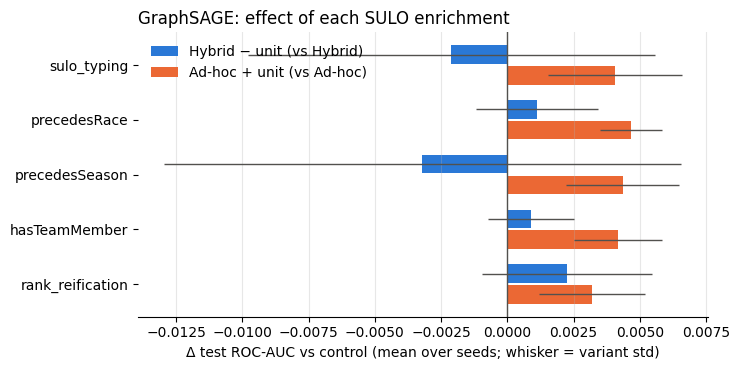

In [8]:
units = list(ABLATION_UNITS)
directions = [
    ("hybrid_minus", "Hybrid − unit (vs Hybrid)", "#2a78d6"),
    ("adhoc_plus", "Ad-hoc + unit (vs Ad-hoc)", "#eb6834"),
]
y = np.arange(len(units))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for offset, (prefix, label, color) in zip((-0.19, 0.19), directions):
    rows = summary.loc[[f"{prefix}_{u}" for u in units]]
    ax.barh(y + offset, rows["delta_test_roc_auc"], height=0.34, color=color, label=label,
            xerr=rows["test_roc_auc_std"], error_kw=dict(elinewidth=1, ecolor="#52514e", capsize=0))
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(y, units)
ax.invert_yaxis()
ax.set_xlabel("Δ test ROC-AUC vs control (mean over seeds; whisker = variant std)")
ax.set_title("GraphSAGE: effect of each SULO enrichment", loc="left")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False, loc="best")
fig.tight_layout()
fig.savefig(OUT_DIR / "ablation_delta_test_roc_auc.png", dpi=200)
plt.show()

## Limitation: runs ended by the epoch cap

A seed whose best epoch is ≥ `EPOCHS − PATIENCE` was cut off by the `EPOCHS` cap while possibly still
improving, so its score may be understated (the same limitation as in the main notebooks).

In [9]:
results[results["best_epoch"] >= EPOCHS - PATIENCE][["variant", "seed", "best_epoch", "val_roc_auc", "test_roc_auc"]]

,variant,seed,best_epoch,val_roc_auc,test_roc_auc
0,hybrid_sulo,0,382,0.823108,0.861394
1,hybrid_sulo,1,399,0.825773,0.863366
2,hybrid_sulo,2,398,0.828279,0.864327
7,adhoc,2,360,0.827416,0.864928
13,hybrid_minus_sulo_typing,3,369,0.822033,0.861795
15,hybrid_minus_precedesRace,0,386,0.819757,0.859595
19,hybrid_minus_precedesRace,4,369,0.824367,0.863959
32,hybrid_minus_rank_reification,2,353,0.827638,0.866775
37,adhoc_plus_sulo_typing,2,380,0.827843,0.866729
39,adhoc_plus_sulo_typing,4,396,0.826221,0.865498
